---
title: 3.1.b Amenaza — Inundación pluvial y de arroyos
short_title: b. Amenaza
---

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/sincelejo/blob/main/book/03_analisis/31_inundacion/b_amenaza.ipynb)

**Reproducible sin red en el checkout.** La fuente preservada y sus limitaciones se describen en el capítulo 2.3.


In [1]:
from pathlib import Path
import sys, subprocess, json
candidatos = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidatos if (p/'src/sincelejo/analisis.py').exists()), None)
if ROOT is None:
    ROOT = Path('/content/sincelejo')
    if not ROOT.exists():
        subprocess.run(['git','clone','https://github.com/mromerot/sincelejo.git',str(ROOT)],check=True)
    subprocess.run([sys.executable,'-m','pip','install','-q','-e',str(ROOT)+'[libro]'],check=True)
sys.path.insert(0,str(ROOT/'src'))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sincelejo.analisis import cargar, indicadores, deficit_trimestral, sensibilidad_calor
clima = cargar(ROOT/'data/raw/power_1991_2025.json')
anual = indicadores(clima)
evidencia = pd.read_json(ROOT/'data/evidencia.json')
plt.rcParams.update({'figure.figsize':(9,4), 'axes.spines.top':False, 'axes.spines.right':False})


## Método

Se calculan Rx1day, Rx5day y días ≥20 mm como contexto. Para modelar inundación se necesita lluvia subdiaria y un modelo lluvia–escorrentía enlazado con una red hidráulica y terreno de detalle. Validar con marcas de agua y eventos fechados. No transformar directamente lluvia diaria en altura de inundación.

,rx1day,rx5day,r20
anio,,,
1991,28.50,82.02,1
1992,32.05,105.11,3
1993,77.98,157.82,14
1994,36.58,132.08,10
1995,40.33,118.41,7
1996,31.90,81.23,3
1997,26.74,85.97,7
1998,43.55,127.79,9
1999,34.01,82.40,6


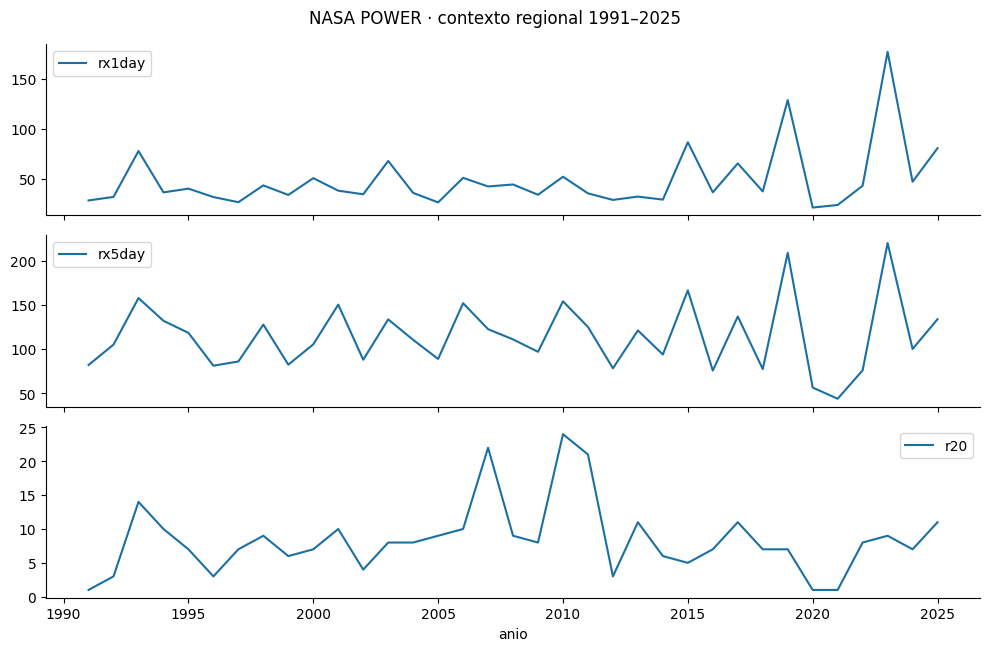

In [2]:
columnas = ['rx1day', 'rx5day', 'r20']
display(anual[columnas].round(2))
anual[columnas].plot(subplots=True,figsize=(10,6.6000000000000005),color='#1a6fa3',legend=True)
plt.suptitle('NASA POWER · contexto regional 1991–2025'); plt.tight_layout(); plt.show()

## Interpretación

Los indicadores describen lluvias regionales; el estado actual del riesgo es un diagnóstico localizado por evidencia. No hay estimación publicada de edificios inundados, población expuesta ni pérdidas.

Para el vínculo con exposición y vulnerabilidad continúe con [riesgo](c_riesgo.ipynb).